In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

In [48]:
DT = 0.1
HORIZON = 100
NUM_SAMPLES = 256
LR = 0.01

In [49]:
key = jax.random.PRNGKey(0)

## Dynamics

In [50]:
def step(state, control):
    x, y, theta = state
    v, w = control
    return jnp.array([
        x + v * jnp.cos(theta) * DT,
        y + v * jnp.sin(theta) * DT,
        theta + w * DT
        ])

def rollout(state0, controls):
    def step_fn(state, control):
        next_state = step(state, control)
        return next_state, next_state
    _, states = jax.lax.scan(step_fn, state0, controls)
    return states

## Cost function

In [73]:
def cost(state0, controls, goal):
    states = rollout(state0, controls)    
    xy = states[:, :2]
    dist2 = jnp.sum((xy - goal) ** 2, axis=1)
    terminal = 10.0 * dist2[-1]
    running = 0.1 * jnp.mean(dist2)                     
    effort = 1e-2 * jnp.sum(controls ** 2)              
    return terminal + running + effort

## Optimizer

In [74]:
state0 = jnp.array([1.0, 0.0, jnp.pi/2])
v, w = 0.0, 0.0
goal = jnp.array([5.0, 5.0])

In [75]:
cost_and_grad = jax.jit(jax.value_and_grad(cost, argnums=1))
controls = jnp.tile(jnp.array([0.8, 0.0]), (HORIZON, 1))
for i in range(500):
    c, g = cost_and_grad(state0, controls, goal)
    controls = controls - LR * g
    if i % 100 == 0:
        print(f"iter {i:2d}  cost {c:.4f}")


iter  0  cost 252.8651
iter 100  cost 1.5748
iter 200  cost 1.5460
iter 300  cost 1.5296
iter 400  cost 1.5153


### Test with a random start

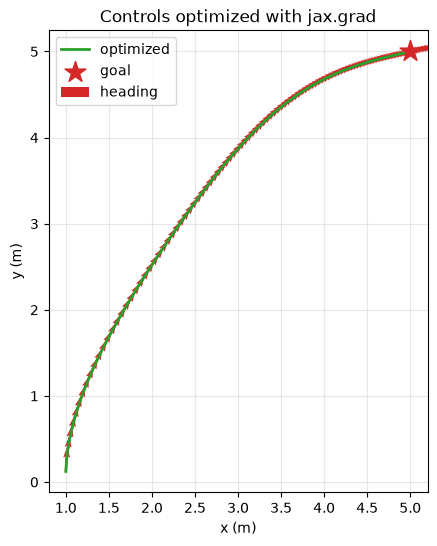

In [76]:
after = jnp.asarray(rollout(state0, controls))
x, y, theta = after[:, 0], after[:, 1], after[:, 2]

_, ax = plt.subplots(figsize=(7, 6))
ax.plot(after[:, 0], after[:, 1], lw=2, color="tab:green", label="optimized")
ax.scatter(*goal, marker="*", s=250, color="tab:red", zorder=3, label="goal")
ax.quiver(x, y, jnp.cos(theta), jnp.sin(theta),
              angles="xy", scale=15, width=0.006, color="tab:red", label="heading")
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Controls optimized with jax.grad")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [77]:
after[-1]
controls[-1]

Array([0.36606935, 0.        ], dtype=float32)

### Batched test with random starts

In [39]:
batched_cost_and_grad = jax.jit(jax.vmap(jax.value_and_grad(cost, argnums=1), in_axes=(None, 0, None)))
turn_rates = jnp.array([-1.0, -0.5, 0.0, 0.5, 1.0])
batched_controls = jnp.stack([jnp.tile(jnp.array([v, w]), (HORIZON, 1)) for w in turn_rates])

In [40]:
for i in range(50):
    c, g = batched_cost_and_grad(state0, batched_controls, goal)
    batched_controls = batched_controls - LR * g
    if i % 10 == 0:
        print(f"iter {i:2d}  costs {jnp.round(jnp.asarray(c), 4)}")

iter  0  costs [505.00058 505.00018 505.      505.00018 505.00058]
iter 10  costs [141.4303   125.562195  62.5369   119.9751   132.3466  ]
iter 20  costs [34.186897 23.199799  7.0301   20.7066   28.1071  ]
iter 30  costs [8.5717    5.634     2.2282999 4.0259    6.0513   ]
iter 40  costs [3.283     8.2296    1.8199999 1.6305    2.175    ]


In [41]:
batched_rollout = jax.jit(jax.vmap(rollout, in_axes=(None, 0)))
batched_trajs = batched_rollout(state0, batched_controls)

In [42]:
batched_trajs.shape

(5, 60, 3)

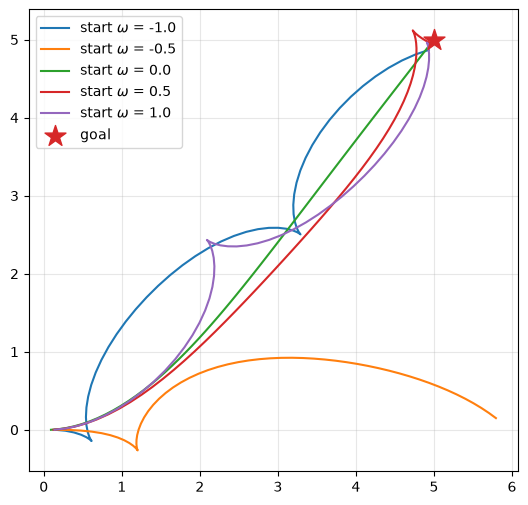

In [43]:
fig, ax = plt.subplots(figsize=(7, 6))
for w, traj in zip(jnp.asarray(turn_rates), jnp.asarray(batched_trajs)):
    ax.plot(traj[:, 0], traj[:, 1], lw=1.5, label=rf"start $\omega$ = {w}")
ax.scatter(*goal, marker="*", s=250, color="tab:red", zorder=3, label="goal")
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
plt.show()